In [16]:
import torch
import os
import torch.nn as nn 
import torch.optim as optim 
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms 
from torchvision import models
from tqdm.notebook import tqdm
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, precision_score, recall_score, f1_score
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
device = torch.device('cuda') if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

Using device: cuda


In [4]:
class FundusDataset(Dataset): 
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_paths = []
        self.labels = []

        self.class_names = [
            'AMD', 'Cataract', 'DR', 'Glaucoma', 
            'Hypertensive_Retinopathy', 'Normal_Fundus', 'Pathological_Myopia'
        ]

        self.class_to_idx = {name: idx for idx, name in enumerate(self.class_names)}
        
        for label in self.class_names:
            class_dir = os.path.join(root_dir, label) 
            if os.path.exists(class_dir):
                for img_name in os.listdir(class_dir):
                    if img_name.lower().endswith(('.jpeg', '.jpg', '.png')):
                        self.image_paths.append(os.path.join(class_dir, img_name))
                        self.labels.append(self.class_to_idx[label])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert('RGB')
        label = self.labels[idx]
        if self.transform:
            image = self.transform(image)
        return image, label

In [5]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [6]:
base_path = '/kaggle/input/datasets/gautamrajiitk/retinal-fundus-image-50k/Retinal Fundus Images'
train_dataset = FundusDataset(root_dir=os.path.join(base_path, 'train'), transform=transform)
val_dataset = FundusDataset(root_dir=os.path.join(base_path, 'val'), transform=transform)
test_dataset = FundusDataset(root_dir=os.path.join(base_path, 'test'), transform=transform)


In [9]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

print(f"Number of training images: {len(train_dataset)} \nNumber of test images: {len(test_dataset)}")


Number of training images: 55446 
Number of test images: 1236


In [10]:
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_dataset.labels),
    y=train_dataset.labels
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)

In [11]:
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, 7) 
model = model.to(device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 164MB/s]


In [12]:
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [13]:
best_val_acc = 0.0 
num_epochs = 10

#plot later
train_loss_history = []
val_loss_history = []
val_acc_history = []

criterion_val = nn.CrossEntropyLoss() 

for epoch in range(num_epochs):
    
    #train
    model.train()
    running_loss = 0.0 

    for images, labels in tqdm(train_loader, desc=f'Epoch {epoch+1}/{num_epochs} Training'):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels) 
        loss.backward() 
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_dataset)
    train_loss_history.append(epoch_loss)
    print(f"Epoch {epoch+1} Training Loss: {epoch_loss:.4f}")

    #val
    model.eval()
    val_running_loss = 0.0
    val_labels = []
    val_preds = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            
            # validation loss
            v_loss = criterion_val(outputs, labels)
            val_running_loss += v_loss.item() * images.size(0)
            
            _, preds = torch.max(outputs, 1)
            val_labels.extend(labels.cpu().numpy())
            val_preds.extend(preds.cpu().numpy())

    epoch_val_loss = val_running_loss / len(val_dataset)
    val_loss_history.append(epoch_val_loss)

    val_acc = accuracy_score(val_labels, val_preds)
    val_acc_history.append(val_acc)
    
    print(f"Epoch {epoch+1} Validation Loss: {epoch_val_loss:.4f} \n Validation Accuracy: {val_acc:.4f}")

    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), 'retinal_fundus_model.pth') # save best model 
        print(f"Best model saved. Validation Accuracy: {best_val_acc:.4f}\n")
    else:
        print(f"Validation Accuracy: {best_val_acc:.4f}\n")

print(f"Training complete. Validation Accuracy: {best_val_acc:.4f}")

Epoch 1/10 Training:   0%|          | 0/1733 [00:00<?, ?it/s]

Epoch 1 Training Loss: 0.4367
Epoch 1 Validation Loss: 0.3778 
 Validation Accuracy: 0.8938
Best model saved. Validation Accuracy: 0.8938



Epoch 2/10 Training:   0%|          | 0/1733 [00:00<?, ?it/s]

Epoch 2 Training Loss: 0.1940
Epoch 2 Validation Loss: 0.4301 
 Validation Accuracy: 0.8915
Validation Accuracy: 0.8938



Epoch 3/10 Training:   0%|          | 0/1733 [00:00<?, ?it/s]

...

Epoch 8 Training Loss: 0.0492
Epoch 8 Validation Loss: 0.5757 
 Validation Accuracy: 0.9007
Validation Accuracy: 0.9238



Epoch 9/10 Training:   0%|          | 0/1733 [00:00<?, ?it/s]

Epoch 9 Training Loss: 0.0453
Epoch 9 Validation Loss: 0.6667 
 Validation Accuracy: 0.9053
Validation Accuracy: 0.9238



Epoch 10/10 Training:   0%|          | 0/1733 [00:00<?, ?it/s]

Epoch 10 Training Loss: 0.0441
Epoch 10 Validation Loss: 0.6395 
 Validation Accuracy: 0.9169
Validation Accuracy: 0.9238

Training complete. Validation Accuracy: 0.9238


In [14]:
# load best saved weights before final testing
model.load_state_dict(torch.load('retinal_fundus_model.pth', map_location=device))
model.eval()

test_labels = []
test_preds = []

with torch.no_grad(): 
    for images, labels in tqdm(test_loader, desc='Testing Loop'):
        images = images.to(device)
        labels = labels.to(device)
                
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
    
        test_labels.extend(labels.cpu().numpy())
        test_preds.extend(preds.cpu().numpy())


accuracy = accuracy_score(test_labels, test_preds)
precision = precision_score(test_labels, test_preds, average='weighted', zero_division=0)
recall = recall_score(test_labels, test_preds, average='weighted', zero_division=0)
f1 = f1_score(test_labels, test_preds, average='weighted', zero_division=0)

print(f"\n Metrics:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

print("Classification Report")
print(classification_report(test_labels, test_preds, target_names=test_dataset.class_names, zero_division=0))

Testing Loop:   0%|          | 0/39 [00:00<?, ?it/s]


 Metrics:
Accuracy: 0.9555
Precision: 0.9580
Recall: 0.9555
F1 Score: 0.9554
Classification Report
                          precision    recall  f1-score   support

                     AMD       0.81      0.97      0.88        77
                Cataract       0.95      0.99      0.97       112
                      DR       1.00      1.00      1.00       516
                Glaucoma       0.88      0.90      0.89       156
Hypertensive_Retinopathy       0.97      0.79      0.87        94
           Normal_Fundus       0.97      0.95      0.96       179
     Pathological_Myopia       0.95      0.92      0.94       102

                accuracy                           0.96      1236
               macro avg       0.93      0.93      0.93      1236
            weighted avg       0.96      0.96      0.96      1236



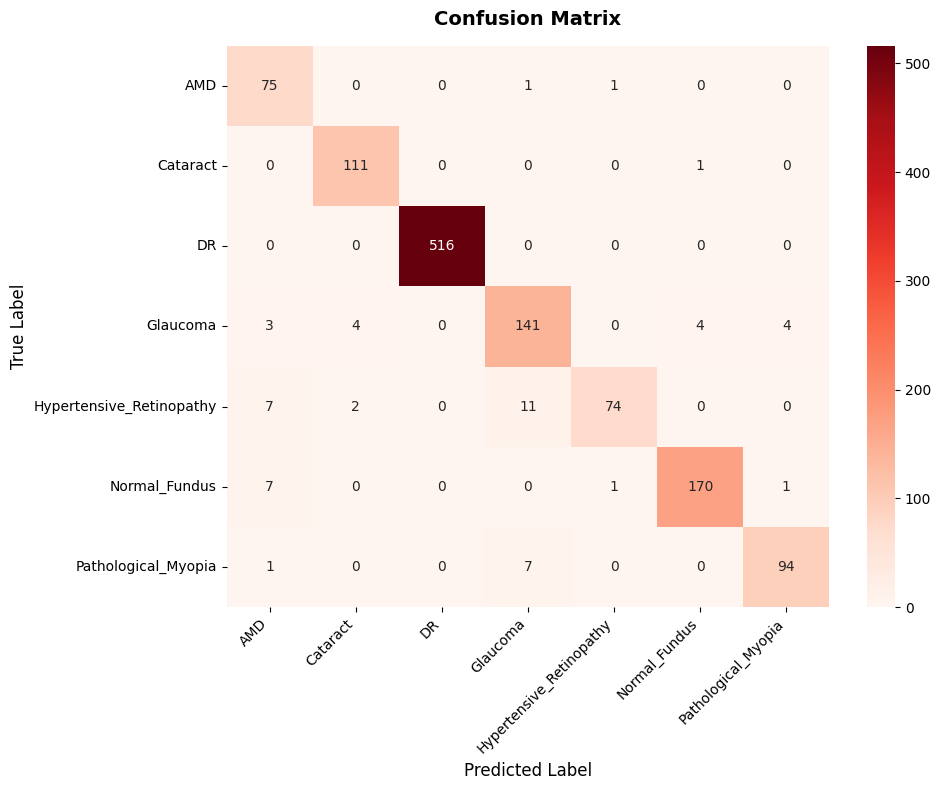

In [18]:
cm = confusion_matrix(test_labels, test_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=test_dataset.class_names, 
            yticklabels=test_dataset.class_names)

plt.title('Confusion Matrix', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

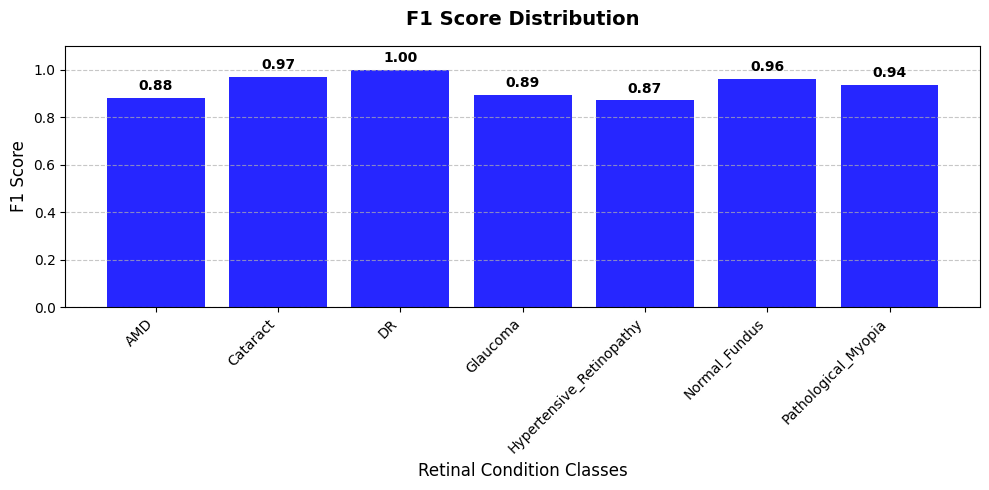

In [21]:
# get classification report as dict to extract indivdiual class F1 scores
report_dict = classification_report(
    test_labels, test_preds, 
    target_names=test_dataset.class_names, 
    output_dict=True, 
    zero_division=0
)


classes = test_dataset.class_names
f1_scores = [report_dict[cls]['f1-score'] for cls in classes]


plt.figure(figsize=(10, 5))
bars = plt.bar(classes, f1_scores, color='blue', alpha=0.85)

plt.title('F1 Score Distribution', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Retinal Condition Classes', fontsize=12)
plt.ylabel('F1 Score', fontsize=12)
plt.ylim(0, 1.1)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

#add no.s on top of the bars
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2.0, yval + 0.02, 
        f'{yval:.2f}', ha='center', va='bottom', fontsize=10, fontweight='semibold'
    )

plt.tight_layout()
plt.show()